# Tarea 1
##Vamos a generar un campograma (mapa de pases) de un jugador específico del archivo `pass_data_Real Madrid_Leganés.csv` para visualizar sus pases en el campo de un jugador concreto. Posteriormente filtraremos, tanto los pases que el jugador consigue dar acia delante como los pases que ha conseguido dar dentro del área, señalando aquellos con éxito y sin éxito.

## Instalación de Librerías y Carga de Datos

Subtarea:
Importar las bibliotecas necesarias y cargar los datos de pase del archivo CSV en un DataFrame de Pandas.

Razonamiento: Importaré las bibliotecas necesarias (pandas, matplotlib.pyplot y Pitch de mplsoccer) y luego cargaré el archivo 'pass_data_Real Madrid_Leganés.csv' en un DataFrame de Pandas llamado df.


In [64]:
!pip install mplsoccer
!pip install cmasher
!pip install highlight_text

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

df = pd.read_csv('/content/pass_data_Real Madrid_Leganés.csv', encoding='latin1')
print("DataFrame loaded successfully. Displaying the first 5 rows:")
df.head()

DataFrame loaded successfully. Displaying the first 5 rows:


,team,player,period,min,sec,pass zone,x,y,x_end,y_end,pass length,pass angle,outcome
0,Real Madrid,Karim Benzema,1,0,1,Back,50.4,49.7,37.6,59.2,14.9,2.7,1
1,Real Madrid,Toni Kroos,1,0,2,Back,38.9,57.1,38.0,45.8,7.7,4.6,1
2,Real Madrid,Luka Modric,1,0,5,Back,32.9,36.9,30.4,53.0,11.3,1.8,1
3,Real Madrid,Casemiro,1,0,6,Back,30.4,53.0,20.7,37.1,14.9,4.0,1
4,Real Madrid,Raphael Varane,1,0,7,Back,20.7,37.1,22.2,7.1,20.5,4.8,1


## Preprocesamiento y filtrado de pases del jugador

### Subtarea:
Filtrar el DataFrame para obtener solo los eventos de pase de un jugador específico.


In [66]:
print(df.info())
print("\nUnique values in 'outcome' column:")
print(df['outcome'].unique())
print("\nUnique values in 'player' column:")
print(df['player'].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1204 entries, 0 to 1203
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   team         1204 non-null   object 
 1   player       1204 non-null   object 
 2   period       1204 non-null   int64  
 3   min          1204 non-null   int64  
 4   sec          1204 non-null   int64  
 5   pass zone    1204 non-null   object 
 6   x            1204 non-null   float64
 7   y            1204 non-null   float64
 8   x_end        1204 non-null   float64
 9   y_end        1204 non-null   float64
 10  pass length  1204 non-null   float64
 11  pass angle   1204 non-null   float64
 12  outcome      1204 non-null   int64  
dtypes: float64(6), int64(4), object(3)
memory usage: 122.4+ KB
None

Unique values in 'outcome' column:
[1 0]

Unique values in 'player' column:
['Karim Benzema' 'Toni Kroos' 'Luka Modric' 'Casemiro' 'Raphael Varane'
 'Daniel Carvajal' 'Thibaut Courtois' 'Sergio

In [75]:
player_name = 'Toni Kroos'
player_passes = df[df['player'] == player_name]

print(f"Filtered passes for {player_name}:\n")
print(player_passes.head())
print(f"\npases totales de {player_name}: {len(player_passes)}")

Filtered passes for Toni Kroos:

           team      player  period  min  sec pass zone     x     y  x_end  \
1   Real Madrid  Toni Kroos       1    0    2      Back  38.9  57.1   38.0   
13  Real Madrid  Toni Kroos       1    0   31    Center  38.2  82.6   50.5   
30  Real Madrid  Toni Kroos       1    2    0      Back  39.2  76.9   32.7   
47  Real Madrid  Toni Kroos       1    2   44    Center  68.6  57.2   69.4   
71  Real Madrid  Toni Kroos       1    4   55      Left  54.1  83.5   63.0   

    y_end  pass length  pass angle  outcome  
1    45.8          7.7         4.6        1  
13   46.0         28.0         5.2        1  
30   89.3         10.8         2.3        1  
47   45.1          8.3         4.8        1  
71   98.3         13.7         0.8        1  

pases totales de Toni Kroos: 112


## Preparación del Campo de Fútbol

### Subtarea:
Inicializa el objeto `Pitch` de `mplsoccer` para dibujar el campo de fútbol.


**Razonamiento**:
Inicializaré un objeto Pitch con parámetros específicos para preparar el dibujo del campo de fútbol, ​​según lo solicitado por la subtarea.



In [76]:
pitch = Pitch(pitch_type='opta', pitch_color='grass', line_color='white', stripe=True)
print("Pitch object initialized successfully.")

Pitch object initialized successfully.


## Visualización de Pases en el Campograma

### Subtarea:
Generar el mapa de pases dibujando el campo de fútbol y representando los pases de los jugadores filtrados.


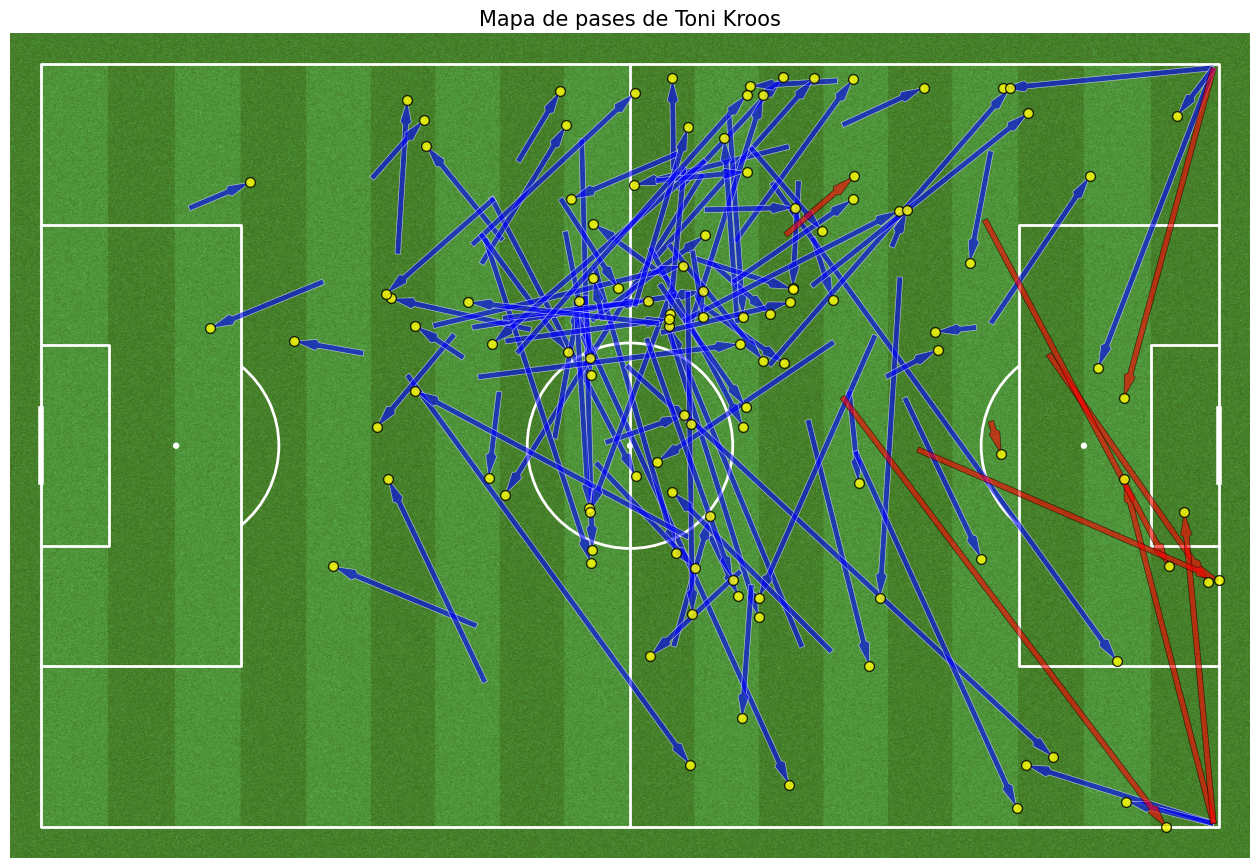

In [77]:
fig, ax = pitch.draw(figsize=(16,11), constrained_layout=True, tight_layout=False)

# Plot pases completados
pitch.arrows(
    player_passes[player_passes['outcome'] == 1]['x'],
    player_passes[player_passes['outcome'] == 1]['y'],
    player_passes[player_passes['outcome'] == 1]['x_end'],
    player_passes[player_passes['outcome'] == 1]['y_end'],
    ax=ax, color='blue', linewidth=0.5, headwidth=2, headlength=4, alpha=0.6, edgecolors='white'
)

# Plot pases incompletos
pitch.arrows(
    player_passes[player_passes['outcome'] == 0]['x'],
    player_passes[player_passes['outcome'] == 0]['y'],
    player_passes[player_passes['outcome'] == 0]['x_end'],
    player_passes[player_passes['outcome'] == 0]['y_end'],
    ax=ax, color='red', linewidth=0.5, headwidth=2, headlength=4, alpha=0.6, edgecolors='black'
)

# Agregamos marcadores amarillos en los puntos finales de todos los pasos para resaltar los destinos

pitch.scatter(

    player_passes['x_end'],
    player_passes['y_end'],
    ax=ax, marker='o', s=50, color='yellow', edgecolors='black', alpha=0.8, zorder=2
)

plt.title(f'Mapa de pases de {player_name}', fontsize=15)
plt.show()

# Tarea
Filtra los pases de Toni Kroos para incluir solo pases hacia adelante (donde `x_end` es mayor que `x`), luego traza estos pases hacia adelante en un campo de fútbol, ​​distinguiendo entre pases exitosos y fallidos con diferentes colores (por ejemplo, azul para exitosos y rojo para fallidos) y agregando marcadores amarillos en el punto final de cada pase para indicar el destino del pase y, finalmente, muestra el gráfico generado.

## filter_forward_passes

### Subtarea:
Filtrar el DataFrame player_passes para incluir solo los pases que avanzan (x_end > x).

In [78]:
player_forward_passes = player_passes[player_passes['x_end'] > player_passes['x']]

print("Forward passes for Toni Kroos:\n")
print(player_forward_passes.head())
print(f"\nPases totales hacia adelante para Toni Kroos: {len(player_forward_passes)}")

Forward passes for Toni Kroos:

           team      player  period  min  sec pass zone     x     y  x_end  \
13  Real Madrid  Toni Kroos       1    0   31    Center  38.2  82.6   50.5   
47  Real Madrid  Toni Kroos       1    2   44    Center  68.6  57.2   69.4   
71  Real Madrid  Toni Kroos       1    4   55      Left  54.1  83.5   63.0   
90  Real Madrid  Toni Kroos       1    6   42      Back  45.9  90.2   46.8   
99  Real Madrid  Toni Kroos       1    7    5      Back  44.5  78.1   46.6   

    y_end  pass length  pass angle  outcome  
13   46.0         28.0         5.2        1  
47   45.1          8.3         4.8        1  
71   98.3         13.7         0.8        1  
90   36.3         36.7         4.7        1  
99   61.5         11.5         4.9        1  

Pases totales hacia adelante para Toni Kroos: 71


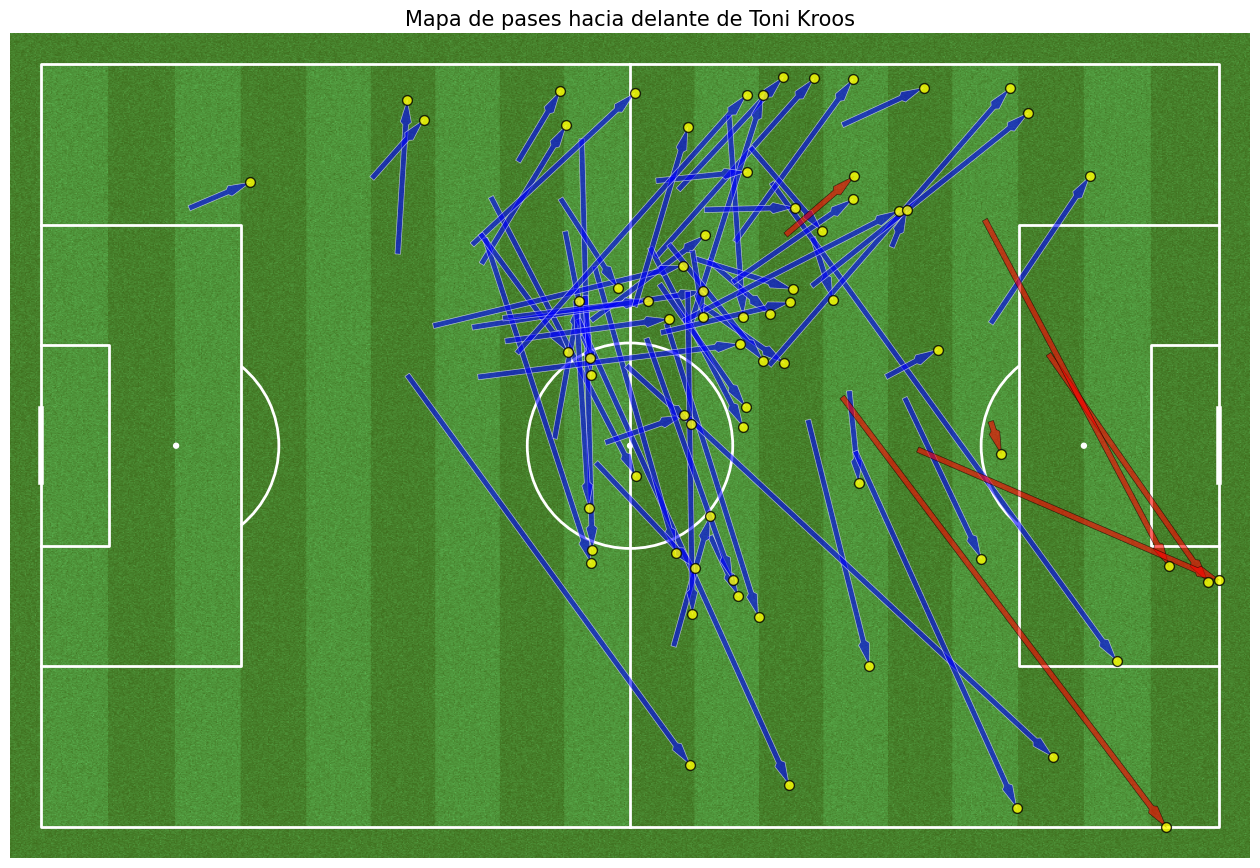

In [79]:
fig, ax = pitch.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)

# Plot completed forward passes
pitch.arrows(
    player_forward_passes[player_forward_passes['outcome'] == 1]['x'],
    player_forward_passes[player_forward_passes['outcome'] == 1]['y'],
    player_forward_passes[player_forward_passes['outcome'] == 1]['x_end'],
    player_forward_passes[player_forward_passes['outcome'] == 1]['y_end'],
    ax=ax, color='blue', linewidth=0.5, headwidth=2, headlength=4, alpha=0.6, edgecolors='white'
)

# Plot incomplete forward passes
pitch.arrows(
    player_forward_passes[player_forward_passes['outcome'] == 0]['x'],
    player_forward_passes[player_forward_passes['outcome'] == 0]['y'],
    player_forward_passes[player_forward_passes['outcome'] == 0]['x_end'],
    player_forward_passes[player_forward_passes['outcome'] == 0]['y_end'],
    ax=ax, color='red', linewidth=0.5, headwidth=2, headlength=4, alpha=0.6, edgecolors='black'
)

# Add yellow markers at the end points of all forward passes
pitch.scatter(
    player_forward_passes['x_end'],
    player_forward_passes['y_end'],
    ax=ax, marker='o', s=50, color='yellow', edgecolors='black', alpha=0.8, zorder=2
)

plt.title(f'Mapa de pases hacia delante de {player_name}', fontsize=15)
plt.show()

## Filtrar pases dentro del área penal

### Subtarea:
Filtrar el DataFrame player_passes para incluir solo los pases que terminan dentro del área penal del oponente.


In [80]:
penalty_area_x_min = 82
penalty_area_y_min = 21.1
penalty_area_y_max = 78.9

player_passes_to_penalty_area = player_passes[
    (player_passes['x_end'] >= penalty_area_x_min) &
    (player_passes['y_end'] >= penalty_area_y_min) &
    (player_passes['y_end'] <= penalty_area_y_max)
]

print("Passes to penalty area for Toni Kroos:\n")
print(player_passes_to_penalty_area.head())
print(f"\nTotal de pases dentro del área de penalti: {len(player_passes_to_penalty_area)}")

Passes to penalty area for Toni Kroos:

            team      player  period  min  sec pass zone     x     y  x_end  \
145  Real Madrid  Toni Kroos       1    9   34    Center  99.5   0.5   91.9   
176  Real Madrid  Toni Kroos       1   11    7    Center  62.0  84.5   91.3   
257  Real Madrid  Toni Kroos       1   18   29    Center  99.5  99.5   91.9   
535  Real Madrid  Toni Kroos       1   38   58    Center  85.5  62.0   99.0   
573  Real Madrid  Toni Kroos       1   42   15    Center  99.5  99.5   89.7   

     y_end  pass length  pass angle  outcome  
145   45.7         31.8         1.8        0  
176   21.8         52.6         5.3        1  
257   56.3         30.4         4.4        0  
535   32.2         24.7         5.3        0  
573   60.2         28.6         4.3        1  

Total de pases dentro del área de penalti: 8


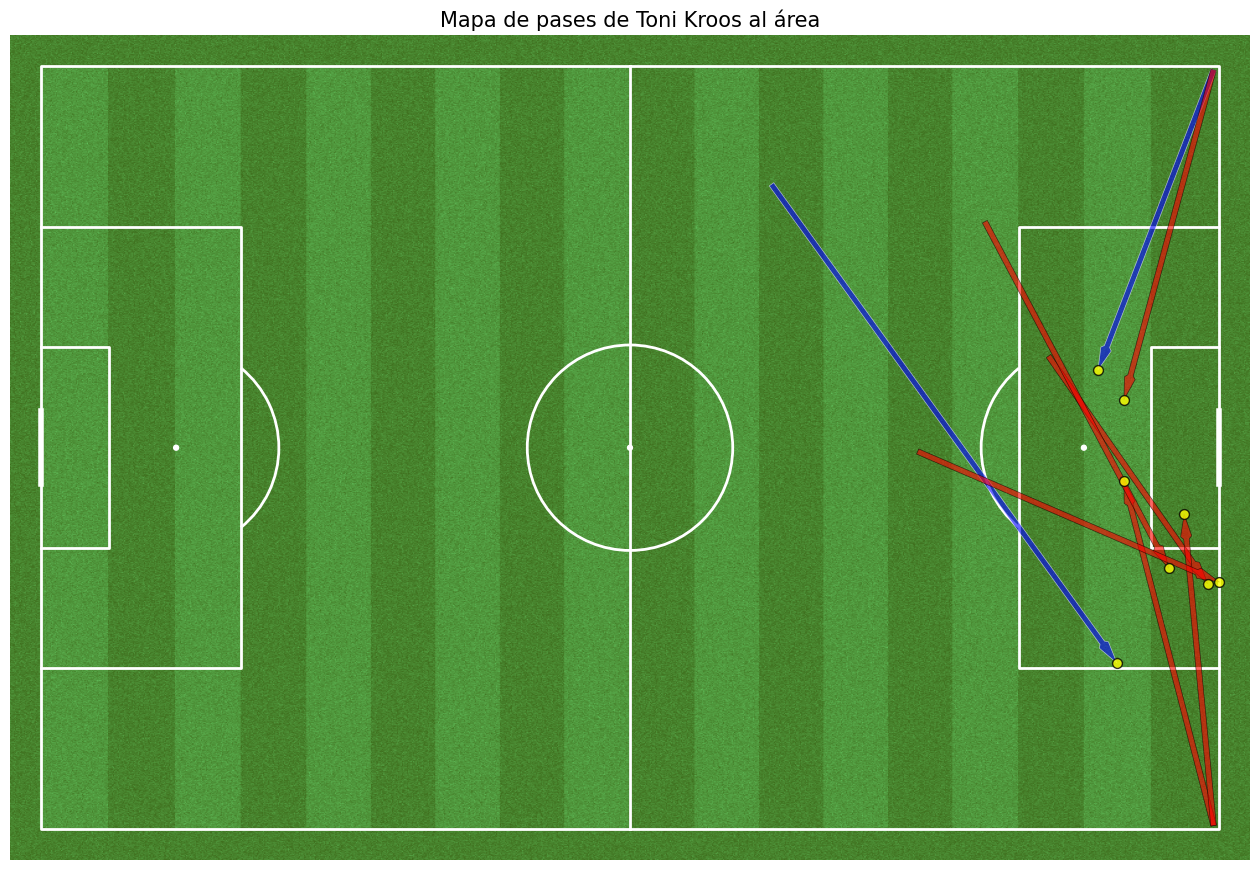

In [81]:
fig, ax = pitch.draw(figsize=(16, 11), constrained_layout=True, tight_layout=False)

# Trazar pases completados en el área penal
pitch.arrows(
    player_passes_to_penalty_area[player_passes_to_penalty_area['outcome'] == 1]['x'],
    player_passes_to_penalty_area[player_passes_to_penalty_area['outcome'] == 1]['y'],
    player_passes_to_penalty_area[player_passes_to_penalty_area['outcome'] == 1]['x_end'],
    player_passes_to_penalty_area[player_passes_to_penalty_area['outcome'] == 1]['y_end'],
    ax=ax, color='blue', linewidth=0.5, headwidth=2, headlength=4, alpha=0.6, edgecolors='white'
)

# Trazar pases incompletos al área penal
pitch.arrows(
    player_passes_to_penalty_area[player_passes_to_penalty_area['outcome'] == 0]['x'],
    player_passes_to_penalty_area[player_passes_to_penalty_area['outcome'] == 0]['y'],
    player_passes_to_penalty_area[player_passes_to_penalty_area['outcome'] == 0]['x_end'],
    player_passes_to_penalty_area[player_passes_to_penalty_area['outcome'] == 0]['y_end'],
    ax=ax, color='red', linewidth=0.5, headwidth=2, headlength=4, alpha=0.6, edgecolors='black'
)


# Agregar marcadores amarillos en los puntos finales de todos los pases al área penal
pitch.scatter(
    player_passes_to_penalty_area['x_end'],
    player_passes_to_penalty_area['y_end'],
    ax=ax, marker='o', s=50, color='yellow', edgecolors='black', alpha=0.8, zorder=2
)

plt.title(f'Mapa de pases de {player_name} al área', fontsize=15)
plt.show()